# Name : Manmath Kornule
# Prn : 202401110045

# Practical No-06: RAG using a Pre-trained LLM
## Domain: MIT Academy of Engineering, CSE (AI/ML) Department

**Objective:** Build a Retrieval-Augmented Generation (RAG) system that answers questions from
MITAoE CSE-AIML department documents, and compare it with the same LLM answering without retrieval.

### Pipeline
Documents → Load → Clean → Chunk → Embed → Vector DB (ChromaDB)
                                                      ↓
User question → Embed → Top-k retrieval → Prompt (question + context) → Gemini → Answer + sources

### Tech stack
| Component | Choice | Why |
|---|---|---|
| Loader | pypdf, python-docx | PDF/DOCX/TXT support |
| Chunking | LangChain RecursiveCharacterTextSplitter | Splits on natural boundaries |
| Embeddings | all-MiniLM-L6-v2 (sentence-transformers) | Free, local, fast, good quality |
| Vector DB | ChromaDB (persistent) | Simple, local, metadata filtering |
| LLM | Gemini (Google AI API) | Pretrained LLM |
| UI | Streamlit | Final demo |

### Rubric map
| Rubric criterion | Sections |
|---|---|
| 1. Processing, chunking, embeddings | 2-5 |
| 2. Vector DB & RAG pipeline | 6-9 |
| 3. Response quality & evaluation | 10 |
| 4. Demo, viva | 11-12 |

## 1. Setup
Install libraries, load the Gemini API key securely, and keep every tunable parameter in one config cell.

In [1]:
!pip -q install pypdf python-docx langchain-text-splitters sentence-transformers chromadb google-genai streamlit pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


In [2]:
import os, re, glob, json, time
from collections import Counter
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from pypdf import PdfReader
from docx import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter

pd.set_option("display.max_colwidth", 120)
print("Imports OK")

Imports OK


In [3]:
# ---- API key: Colab secret -> environment variable -> manual prompt ----
try:
    from google.colab import userdata
    GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
except Exception:
    GEMINI_API_KEY = os.environ.get("GEMINI_API_KEY")

if not GEMINI_API_KEY:
    import getpass
    GEMINI_API_KEY = getpass.getpass("Enter Gemini API key: ")

os.environ["GEMINI_API_KEY"] = GEMINI_API_KEY
print("API key loaded:", bool(GEMINI_API_KEY))

Enter Gemini API key: ··········
API key loaded: True


In [21]:
# ---- Central configuration ----
DATA_DIR        = "data/mitaoe_cse_aiml"     # put your documents here
CHROMA_DIR      = "chroma_db"
COLLECTION_NAME = "mitaoe_cse_aiml"

CHUNK_SIZE      = 500      # characters (final value chosen in Section 4)
CHUNK_OVERLAP   = 100
TOP_K           = 4

EMBED_MODEL     = "sentence-transformers/all-MiniLM-L6-v2"
GEMINI_MODEL    = "gemini-3.5-flash-lite"   # change to whichever Flash model your key can access

os.makedirs(DATA_DIR, exist_ok=True)
print(f"Put your files in: {DATA_DIR}")

Put your files in: data/mitaoe_cse_aiml


## 2. Document Collection
**Domain:** MITAoE CSE (AI/ML) department documents (syllabus, curriculum, rules, etc.).

**Why RAG fits this domain:** this information is private and institution-specific. A general LLM
was not trained on it, so without retrieval it will guess or hallucinate. This makes the benefit of
RAG measurable in Section 10.

We load every PDF/DOCX/TXT file page by page and keep metadata (`source`, `page`) so answers can be cited.

In [6]:
def load_pdf(path):
    reader = PdfReader(path)
    return [{"source": Path(path).name, "page": i + 1, "text": page.extract_text() or ""}
            for i, page in enumerate(reader.pages)]

def load_docx(path):
    doc = Document(path)
    parts = [p.text for p in doc.paragraphs if p.text.strip()]
    for table in doc.tables:                       # syllabus docs often use tables
        for row in table.rows:
            parts.append(" | ".join(c.text.strip() for c in row.cells))
    return [{"source": Path(path).name, "page": 1, "text": "\n".join(parts)}]

def load_txt(path):
    return [{"source": Path(path).name, "page": 1,
             "text": Path(path).read_text(encoding="utf-8", errors="ignore")}]

LOADERS = {".pdf": load_pdf, ".docx": load_docx, ".txt": load_txt, ".md": load_txt}

def load_documents(data_dir):
    pages = []
    for path in sorted(glob.glob(f"{data_dir}/**/*.*", recursive=True)):
        ext = Path(path).suffix.lower()
        if ext in LOADERS:
            try:
                pages.extend(LOADERS[ext](path))
            except Exception as e:
                print(f"Failed: {path} -> {e}")
    return pages

raw_pages = load_documents(DATA_DIR)
print(f"Loaded {len(raw_pages)} pages from {len({p['source'] for p in raw_pages})} files")

Loaded 42 pages from 1 files


In [7]:
# Collection summary
df_docs = pd.DataFrame(raw_pages)
df_docs["chars"] = df_docs["text"].str.len()
summary = df_docs.groupby("source").agg(pages=("page", "count"),
                                        total_chars=("chars", "sum"),
                                        avg_chars_per_page=("chars", "mean")).round(0)
display(summary)

# Warning for scanned PDFs (no extractable text)
empty = df_docs[df_docs["chars"] < 50]
print(f"\nPages with almost no text: {len(empty)}")
if len(empty):
    print("These files may be scanned images and need OCR:", empty["source"].unique().tolist())

,pages,total_chars,avg_chars_per_page
source,,,
Copy of AIML_Newsletter-compressed.pdf,42,35728,851.0



Pages with almost no text: 2
These files may be scanned images and need OCR: ['Copy of AIML_Newsletter-compressed.pdf']


In [8]:
# Sample page
sample = raw_pages[0]
print(f"Source: {sample['source']} | Page: {sample['page']}\n")
print(sample["text"][:800])

Source: Copy of AIML_Newsletter-compressed.pdf | Page: 1

FUSION MINDS
Academic Year 2025-26
Computer Science and Engineering (AIML) 
Department
Newsletter


## 3. Cleaning & Preprocessing
PDF extraction is noisy. We:
1. Fix words broken by hyphenation at line ends
2. Remove repeating headers/footers (lines that appear on many pages of the same file)
3. Remove standalone page numbers
4. Normalize whitespace

Clean input means cleaner embeddings and better retrieval.

In [9]:
def find_repeating_lines(pages, threshold=0.4):
    """Lines appearing on >= threshold of a file's pages are treated as header/footer."""
    by_file = {}
    for p in pages:
        by_file.setdefault(p["source"], []).append(p["text"])
    repeating = {}
    for src, texts in by_file.items():
        if len(texts) < 4:
            repeating[src] = set()
            continue
        counter = Counter()
        for t in texts:
            counter.update({ln.strip() for ln in t.split("\n") if ln.strip()})
        repeating[src] = {ln for ln, c in counter.items() if c / len(texts) >= threshold}
    return repeating

def clean_text(text, repeated=frozenset()):
    text = re.sub(r"(\w)-\n(\w)", r"\1\2", text)                     # de-hyphenate
    lines = []
    for ln in text.split("\n"):
        s = ln.strip()
        if s in repeated:                                            # header/footer
            continue
        if re.fullmatch(r"(page\s*)?\d{1,3}(\s*(of|/)\s*\d{1,3})?", s, flags=re.I):
            continue                                                 # page numbers
        lines.append(s)
    text = "\n".join(lines)
    text = re.sub(r"[ \t]+", " ", text)                              # spaces
    text = re.sub(r"\n{3,}", "\n\n", text)                           # blank lines
    return text.strip()

repeating = find_repeating_lines(raw_pages)
for src, lines in repeating.items():
    if lines:
        print(f"{src}: removing {len(lines)} repeating lines, e.g. {list(lines)[:2]}")

clean_pages = []
for p in raw_pages:
    txt = clean_text(p["text"], repeating.get(p["source"], set()))
    if len(txt) > 30:                                                # drop empty pages
        clean_pages.append({**p, "text": txt})

print(f"\nPages before: {len(raw_pages)} | after cleaning: {len(clean_pages)}")


Pages before: 42 | after cleaning: 41


In [10]:
# Before vs after on one sample page
i = min(2, len(raw_pages) - 1)
orig = raw_pages[i]
cleaned = next((p for p in clean_pages if p["source"] == orig["source"] and p["page"] == orig["page"]), None)

print("=== BEFORE ===\n", orig["text"][:600])
print("\n=== AFTER ===\n", cleaned["text"][:600] if cleaned else "(page removed as empty)")
print(f"\nChars: {len(orig['text'])} -> {len(cleaned['text']) if cleaned else 0}")

=== BEFORE ===
 A future-focused academic environment that
empowers students through inclusive education,
responsible innovation, and a commitment to
driving societal progress professional engineers,
to cater to the changing needs of techno-society.
Innovation & Research: Advancing AI through
quality education and research, foster
innovation, and prepare ethical, industry-ready
professionals to solve real-world challenges.
Academia-Industry Collaboration: Empowering
students with industry-relevant AI skills
through industry collaboration
Ethical Solutions: Developing ethical and
transformative AI solutions fo

=== AFTER ===
 A future-focused academic environment that
empowers students through inclusive education,
responsible innovation, and a commitment to
driving societal progress professional engineers,
to cater to the changing needs of techno-society.
Innovation & Research: Advancing AI through
quality education and research, foster
innovation, and prepare ethical, industry-ready
pr

## 4. Chunking
**Why chunk?** Embedding models and LLM prompts work best on focused passages. A whole page mixes
topics, which dilutes the embedding and wastes prompt space. Tiny chunks lose context.

**Method:** `RecursiveCharacterTextSplitter` tries to split on paragraph → line → sentence → word
boundaries, so chunks stay semantically coherent.

**Overlap:** repeated text between neighbouring chunks prevents a fact being cut in half at a boundary.

We test three chunk sizes and compare them before choosing one.

In [11]:
def make_chunks(pages, chunk_size, chunk_overlap):
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
        separators=["\n\n", "\n", ". ", " ", ""],
    )
    chunks = []
    for p in pages:
        for j, piece in enumerate(splitter.split_text(p["text"])):
            chunks.append({
                "id": f"{p['source']}_p{p['page']}_c{j}",
                "text": piece,
                "source": p["source"],
                "page": p["page"],
            })
    return chunks

# ---- Experiment: 3 configurations ----
configs = [(300, 60), (500, 100), (1000, 200)]
results, chunk_sets = [], {}
for size, ov in configs:
    ch = make_chunks(clean_pages, size, ov)
    chunk_sets[(size, ov)] = ch
    lens = [len(c["text"]) for c in ch]
    results.append({"chunk_size": size, "overlap": ov, "num_chunks": len(ch),
                    "avg_len": round(sum(lens) / len(lens)), "min_len": min(lens), "max_len": max(lens)})

display(pd.DataFrame(results))

,chunk_size,overlap,num_chunks,avg_len,min_len,max_len
0,300,60,163,245,39,299
1,500,100,103,391,40,496
2,1000,200,61,638,40,1000


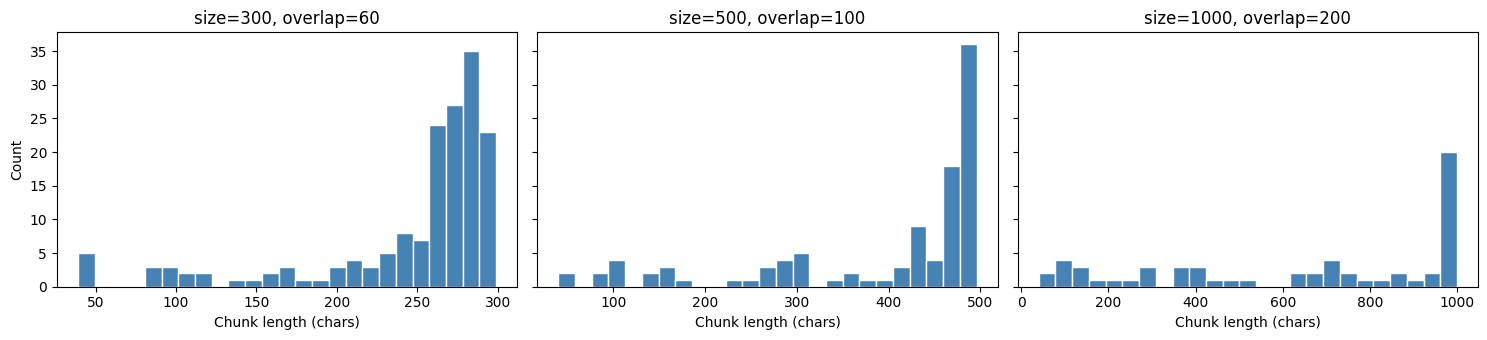

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, (size, ov) in zip(axes, configs):
    ax.hist([len(c["text"]) for c in chunk_sets[(size, ov)]], bins=25, color="steelblue", edgecolor="white")
    ax.set_title(f"size={size}, overlap={ov}")
    ax.set_xlabel("Chunk length (chars)")
axes[0].set_ylabel("Count")
plt.tight_layout(); plt.show()

In [13]:
# Inspect sample chunks side by side
for size, ov in configs:
    ch = chunk_sets[(size, ov)]
    mid = ch[len(ch) // 2]
    print(f"--- size={size} | {mid['source']} p{mid['page']} ---")
    print(mid["text"], "\n")

--- size=300 | Copy of AIML_Newsletter-compressed.pdf p19 ---
Department (CSE-AIML), and coordinated by Prof.
Deepti Bhirud. This initiative marks an important
milestone in creating a collaborative platform for
students to strengthen their expertise in
algorithms, coding, and emerging AI technologies.
ALGOVEDAS aims to foster innovation, peer 

--- size=500 | Copy of AIML_Newsletter-compressed.pdf p19 ---
problem-solving abilities and explore advanced
technical concepts beyond the classroom
curriculum.
As part of the inauguration, an insightful
cybersecurity session was conducted by students
from Symbiosis Skills and Professional University.
The session covered key aspects of cyber threats,
basics of ethical hacking, and the importance of
digital security in today’s technology-driven
world. The interactive talk provided practical
awareness and encouraged students to adopt 

--- size=1000 | Copy of AIML_Newsletter-compressed.pdf p19 ---
problem-solving abilities and explore advanced
tec

### Decision: chunk size 500 characters, overlap 100
Evidence from the experiment above:

| Config | Chunks | Avg length | Observation |
|---|---|---|---|
| 300 / 60 | 163 | 245 chars | Too fragmented. The sample chunk on page 19 ends mid-sentence, so facts get split across chunks. |
| **500 / 100** | **103** | **391 chars** | One event or paragraph per chunk, so each embedding stays focused on a single topic. |
| 1000 / 200 | 61 | 638 chars | Mixes unrelated content. The sample merged the ALGOVEDAS inauguration text with the "CLUB Members" block. |

**Second reason:** `all-MiniLM-L6-v2` truncates input at 256 tokens. A 500-character chunk is far below that limit, whereas 1000-character chunks get closer to it. This is verified numerically in Section 5.1.

In [14]:
# Final chunking with the chosen config
chunks = make_chunks(clean_pages, CHUNK_SIZE, CHUNK_OVERLAP)
print(f"Final: {len(chunks)} chunks (size={CHUNK_SIZE}, overlap={CHUNK_OVERLAP})")
print(json.dumps(chunks[0], indent=2))

Final: 103 chunks (size=500, overlap=100)
{
  "id": "Copy of AIML_Newsletter-compressed.pdf_p1_c0",
  "text": "FUSION MINDS\nAcademic Year 2025-26\nComputer Science and Engineering (AIML)\nDepartment\nNewsletter",
  "source": "Copy of AIML_Newsletter-compressed.pdf",
  "page": 1
}


### 4.1 Interactive chunk analysis
Static histograms hide detail. With Plotly you can hover over bars, toggle configurations by clicking the legend, and zoom. We also add a chunk browser so you can read any chunk.

In [15]:
!pip -q install plotly ipywidgets scikit-learn tqdm

In [16]:
import html, random
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
from tqdm.auto import tqdm
print("Visualization libraries ready")

Visualization libraries ready


In [17]:
# Chunk length distribution for all 3 configurations (click legend items to toggle)
rows = []
for (size, ov), ch in chunk_sets.items():
    for c in ch:
        rows.append({"config": f"size={size}, overlap={ov}", "chars": len(c["text"]), "page": c["page"]})
df_len = pd.DataFrame(rows)

fig = px.histogram(df_len, x="chars", color="config", barmode="overlay", opacity=0.65,
                   nbins=40, marginal="box",
                   title="Chunk length distribution by configuration (click legend to toggle)")
fig.update_layout(template="plotly_white", xaxis_title="Chunk length (characters)", yaxis_title="Number of chunks")
fig.show()

# Chunks per page for the FINAL configuration
per_page = pd.DataFrame(chunks).groupby("page").size().reset_index(name="num_chunks")
fig = px.bar(per_page, x="page", y="num_chunks", title=f"Chunks per page (final: size={CHUNK_SIZE}, overlap={CHUNK_OVERLAP})")
fig.update_layout(template="plotly_white")
fig.show()

In [18]:
# Chunk browser: drag the slider to read any chunk
chunk_slider = widgets.IntSlider(value=0, min=0, max=len(chunks) - 1, description="Chunk #",
                                 continuous_update=False, layout=widgets.Layout(width="60%"))
chunk_out = widgets.Output()

def show_chunk(change=None):
    with chunk_out:
        clear_output(wait=True)
        c = chunks[chunk_slider.value]
        print(f"ID: {c['id']} | page {c['page']} | {len(c['text'])} chars")
        print("-" * 60)
        print(c["text"])

chunk_slider.observe(show_chunk, names="value")
display(chunk_slider, chunk_out)
show_chunk()

IntSlider(value=0, continuous_update=False, description='Chunk #', layout=Layout(width='60%'), max=102)

Output()

## 5. Embeddings
**What is an embedding?** A fixed-length vector (here 384 numbers) that represents the *meaning* of a text.
Texts with similar meaning get vectors that point in similar directions, so "similar meaning" becomes "small angle".

**Model:** `all-MiniLM-L6-v2`
- Free and runs locally (no API quota used for retrieval)
- 384 dimensions, fast on CPU
- Trained for semantic similarity and search
- Max input 256 tokens (our chunks are well below this)

**Similarity measure:** cosine similarity. We normalize vectors to length 1, so cosine similarity equals the dot product.

In [19]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer(EMBED_MODEL)
print("Embedding dimension :", embedder.get_sentence_embedding_dimension())
print("Max sequence length :", embedder.max_seq_length, "tokens")

# Verify that our chunks fit inside the model's limit
tok = embedder.tokenizer
token_lens = [len(tok.encode(c["text"])) for c in chunks]
print(f"Chunk token length  : mean={np.mean(token_lens):.0f}, max={max(token_lens)} "
      f"(limit {embedder.max_seq_length}) -> truncated chunks: {sum(t > embedder.max_seq_length for t in token_lens)}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding dimension : 384
Max sequence length : 256 tokens
Chunk token length  : mean=78, max=153 (limit 256) -> truncated chunks: 0


/tmp/ipykernel_1190/224904105.py:4: FutureWarning:

The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.



### 5.1 Sanity check: does the model understand meaning?
Five sentences: the first three are related (AI/ML activities), the last two are unrelated.
If embeddings work, related pairs score high and unrelated pairs score low.

In [22]:
sentences = [
    "The AIML department organised a workshop on machine learning.",
    "A session on artificial intelligence was conducted for students.",
    "Students participated in a coding competition.",
    "The cafeteria serves lunch at noon.",
    "Heavy rain is expected in Pune tomorrow.",
]
labels = ["ML workshop", "AI session", "Coding contest", "Cafeteria lunch", "Rain forecast"]

emb_s = embedder.encode(sentences, normalize_embeddings=True)
sim = emb_s @ emb_s.T

fig = px.imshow(sim, x=labels, y=labels, text_auto=".2f", color_continuous_scale="Blues",
                zmin=0, zmax=1, title="Cosine similarity between sample sentences (hover for values)")
fig.update_layout(template="plotly_white")
fig.show()

### 5.2 Embed all chunks
Each chunk becomes one 384-dimensional vector. `normalize_embeddings=True` makes cosine similarity equal to the dot product.

In [23]:
texts = [c["text"] for c in chunks]
t0 = time.time()
embeddings = embedder.encode(texts, batch_size=32, normalize_embeddings=True, show_progress_bar=True)
print(f"Embeddings shape: {embeddings.shape}  |  time: {time.time() - t0:.1f}s")
print("Vector norm (should be ~1):", np.linalg.norm(embeddings[0]).round(4))
print("First 8 values of chunk 0:", embeddings[0][:8].round(3))

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Embeddings shape: (103, 384)  |  time: 0.4s
Vector norm (should be ~1): 1.0
First 8 values of chunk 0: [-0.091 -0.039 -0.001  0.033  0.011 -0.086 -0.015 -0.052]


### 5.3 Visualizing the embedding space (interactive)
384 dimensions cannot be plotted, so we project to 2D/3D.
- **PCA**: linear, preserves global structure
- **t-SNE**: non-linear, preserves local neighbourhoods (clusters)

Each dot is a chunk, coloured by page number. **Hover** to read the chunk, **zoom** with the mouse, and use the **buttons** to switch projection.
Chunks about the same topic should sit close together.

In [24]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

pca = PCA(n_components=2, random_state=42)
xy_pca = pca.fit_transform(embeddings)
perp = max(5, min(30, len(chunks) // 4))
xy_tsne = TSNE(n_components=2, perplexity=perp, random_state=42, init="pca", metric="cosine").fit_transform(embeddings)

df_vis = pd.DataFrame({
    "id": [c["id"] for c in chunks],
    "page": [c["page"] for c in chunks],
    "preview": [c["text"][:200].replace("\n", " ") for c in chunks],
    "x_pca": xy_pca[:, 0], "y_pca": xy_pca[:, 1],
    "x_tsne": xy_tsne[:, 0], "y_tsne": xy_tsne[:, 1],
})

def projection_trace(xc, yc, name, visible, showscale):
    return go.Scatter(
        x=df_vis[xc], y=df_vis[yc], mode="markers", name=name, visible=visible,
        marker=dict(size=9, color=df_vis["page"], colorscale="Viridis", showscale=showscale,
                    colorbar=dict(title="Page"), line=dict(width=0.5, color="white")),
        text=df_vis["preview"], customdata=df_vis["page"],
        hovertemplate="<b>Page %{customdata}</b><br>%{text}<extra></extra>")

fig = go.Figure([projection_trace("x_pca", "y_pca", "PCA", True, True),
                 projection_trace("x_tsne", "y_tsne", "t-SNE", False, False)])
fig.update_layout(
    template="plotly_white", height=600, title="Chunk embedding space (PCA)",
    updatemenus=[dict(type="buttons", direction="right", x=0.0, y=1.12, buttons=[
        dict(label="PCA", method="update", args=[{"visible": [True, False]}, {"title": "Chunk embedding space (PCA)"}]),
        dict(label="t-SNE", method="update", args=[{"visible": [False, True]}, {"title": "Chunk embedding space (t-SNE)"}]),
    ])])
fig.show()
print("PCA variance explained by 2 components:", pca.explained_variance_ratio_.sum().round(3))

PCA variance explained by 2 components: 0.157


In [25]:
# 3D view: rotate with the mouse
pca3 = PCA(n_components=3, random_state=42)
xyz = pca3.fit_transform(embeddings)
df3 = df_vis[["id", "page", "preview"]].copy()
df3["x"], df3["y"], df3["z"] = xyz[:, 0], xyz[:, 1], xyz[:, 2]

fig = px.scatter_3d(df3, x="x", y="y", z="z", color="page", color_continuous_scale="Viridis",
                    hover_name="id", hover_data={"preview": True, "x": False, "y": False, "z": False, "page": False},
                    title="3D PCA of chunk embeddings (drag to rotate)")
fig.update_traces(marker=dict(size=4))
fig.update_layout(height=600)
fig.show()

## 6. Vector Database (ChromaDB)
A vector database stores embeddings and answers one question quickly: *"which stored vectors are closest to this query vector?"*

**Why ChromaDB:** it runs locally, persists to disk, stores text + metadata next to each vector, and uses an HNSW graph index for fast approximate nearest-neighbour search.

**Design:**
- One collection with `hnsw:space = cosine`
- Per chunk: `id`, `document` (text), `embedding`, `metadata` (source, page)
- We pass our own embeddings, so the same model embeds both chunks and queries
- Distance returned = `1 - cosine similarity`, so we convert back to a similarity score

In [26]:
import chromadb

chroma_client = chromadb.PersistentClient(path=CHROMA_DIR)
try:                                   # fresh start so re-running the notebook never duplicates data
    chroma_client.delete_collection(COLLECTION_NAME)
except Exception:
    pass

collection = chroma_client.create_collection(name=COLLECTION_NAME, metadata={"hnsw:space": "cosine"})

BATCH = 64
for i in tqdm(range(0, len(chunks), BATCH), desc="Indexing"):
    batch = chunks[i:i + BATCH]
    collection.add(
        ids=[c["id"] for c in batch],
        documents=[c["text"] for c in batch],
        embeddings=embeddings[i:i + BATCH].tolist(),
        metadatas=[{"source": c["source"], "page": c["page"]} for c in batch],
    )

print("Indexed chunks:", collection.count())

Indexing:   0%|          | 0/2 [00:00<?, ?it/s]

Indexed chunks: 103


In [27]:
# Persistence check: open the database again from disk, as a new session would
reloaded = chromadb.PersistentClient(path=CHROMA_DIR).get_collection(COLLECTION_NAME)
print("Chunks after reload from disk:", reloaded.count())

peek = collection.get(limit=3, include=["documents", "metadatas"])
for i in range(3):
    print(peek["ids"][i], peek["metadatas"][i], "->", peek["documents"][i][:80].replace("\n", " "), "...")

Chunks after reload from disk: 103
Copy of AIML_Newsletter-compressed.pdf_p1_c0 {'page': 1, 'source': 'Copy of AIML_Newsletter-compressed.pdf'} -> FUSION MINDS Academic Year 2025-26 Computer Science and Engineering (AIML) Depar ...
Copy of AIML_Newsletter-compressed.pdf_p2_c0 {'page': 2, 'source': 'Copy of AIML_Newsletter-compressed.pdf'} -> To be a new age learning center for holistic development of students into profes ...
Copy of AIML_Newsletter-compressed.pdf_p2_c1 {'page': 2, 'source': 'Copy of AIML_Newsletter-compressed.pdf'} -> transforming educational practices. Promoting an ethical and moral values by inv ...


In [28]:
# Raw query test + metadata filtering
def raw_query(question, k=4, where=None):
    q = embedder.encode([question], normalize_embeddings=True)
    res = collection.query(query_embeddings=q.tolist(), n_results=k, where=where,
                           include=["documents", "metadatas", "distances"])
    return pd.DataFrame({
        "rank": range(1, len(res["ids"][0]) + 1),
        "similarity": [round(1 - d, 3) for d in res["distances"][0]],
        "page": [m["page"] for m in res["metadatas"][0]],
        "chunk": [d[:110].replace("\n", " ") + "..." for d in res["documents"][0]],
    })

print("Query: 'Who coordinated the ALGOVEDAS club?'")
display(raw_query("Who coordinated the ALGOVEDAS club?"))

print("Same query, restricted to pages 1-10 via metadata filter:")
display(raw_query("Who coordinated the ALGOVEDAS club?", where={"page": {"$lte": 10}}))

Query: 'Who coordinated the ALGOVEDAS club?'


,rank,similarity,page,chunk
0,1,0.634,19,emerge as a hub of innovation and technical growth. Date : 7th November 2025 CLUB Members ALGOVEDAS...
1,2,0.562,19,"students to strengthen their expertise in algorithms, coding, and emerging AI technologies. ALGOVEDAS aims to ..."
2,3,0.488,19,world. The interactive talk provided practical awareness and encouraged students to adopt secure coding practi...
3,4,0.463,40,Association for the Advancement of Artificial Intelligence The Department’s Club AA A I CLUBS ALGOVEDAS...


Same query, restricted to pages 1-10 via metadata filter:


,rank,similarity,page,chunk
0,1,0.267,6,"FUSION MINDS ASTRA Association for Students in Technology, Research & AI Student’s Program Algovedas AIML Stud..."
1,2,0.249,7,Sr. No. Content 1 Institute's Vision & Mission 2 2 Department’s Vision & Mission 3 3 President’s note 4 4 Edit...
2,3,0.240,7,9.1 Faculty Achievements 23 9.2 Student Achievements 24 9.3 Other Participations 25 9.4 Sports Corner 31 10 Ap...
3,4,0.204,10,"technologist, and co-founder of Career Credentials, and witnessed participation from 92 students. The session ..."


## 7. Retrieval Module
`retrieve(query, k)` is the **R** in RAG: embed the question, search the vector DB, return the top-k chunks with similarity scores and page numbers.

The map below shows the query (gold star) in the same embedding space as the chunks. Retrieved chunks are red, with dotted lines to the query.
A good retrieval puts the star near the red points.

In [29]:
def retrieve(query, k=TOP_K, where=None):
    """Return the top-k most similar chunks for a query."""
    q = embedder.encode([query], normalize_embeddings=True)[0]
    res = collection.query(query_embeddings=[q.tolist()], n_results=k, where=where,
                           include=["documents", "metadatas", "distances"])
    return [{"id": res["ids"][0][i],
             "text": res["documents"][0][i],
             "source": res["metadatas"][0][i]["source"],
             "page": res["metadatas"][0][i]["page"],
             "score": 1 - res["distances"][0][i]}
            for i in range(len(res["ids"][0]))]

print(retrieve("When was ALGOVEDAS inaugurated?", k=2)[0])

{'id': 'Copy of AIML_Newsletter-compressed.pdf_p19_c3', 'text': 'world. The interactive talk provided practical\nawareness and encouraged students to adopt\nsecure coding practices and responsible online\nbehavior.\nThe inauguration of ALGOVEDAS was both\ninformative and inspiring, setting a strong\nfoundation for future technical initiatives within\nthe AIML department.\nWith visionary leadership, dedicated coordination, and\nenthusiastic student participation, ALGOVEDAS is set to\nemerge as a hub of innovation and technical growth.\nDate : 7th November 2025', 'source': 'Copy of AIML_Newsletter-compressed.pdf', 'page': 19, 'score': 0.5780380964279175}


In [30]:
def plot_query_map(query, k=TOP_K):
    hits = retrieve(query, k)
    q_xy = pca.transform(embedder.encode([query], normalize_embeddings=True))[0]
    score_by_id = {h["id"]: h["score"] for h in hits}
    mask_hit = df_vis["id"].isin(score_by_id)
    others, top = df_vis[~mask_hit], df_vis[mask_hit].copy()
    top["score"] = top["id"].map(score_by_id)

    fig = make_subplots(rows=1, cols=2, column_widths=[0.62, 0.38],
                        subplot_titles=("Query vs chunks (PCA map)", "Similarity of retrieved chunks"))
    fig.add_trace(go.Scatter(x=others["x_pca"], y=others["y_pca"], mode="markers", name="other chunks",
                             marker=dict(size=7, color="lightgrey"), text=others["preview"], customdata=others["page"],
                             hovertemplate="Page %{customdata}<br>%{text}<extra></extra>"), row=1, col=1)
    for _, r in top.iterrows():
        fig.add_trace(go.Scatter(x=[q_xy[0], r["x_pca"]], y=[q_xy[1], r["y_pca"]], mode="lines",
                                 line=dict(width=1, dash="dot", color="crimson"),
                                 showlegend=False, hoverinfo="skip"), row=1, col=1)
    fig.add_trace(go.Scatter(x=top["x_pca"], y=top["y_pca"], mode="markers+text", name="retrieved",
                             text=[f"{s:.2f}" for s in top["score"]], textposition="top center",
                             marker=dict(size=13, color="crimson"), customdata=top["preview"],
                             hovertemplate="%{customdata}<extra>retrieved</extra>"), row=1, col=1)
    fig.add_trace(go.Scatter(x=[q_xy[0]], y=[q_xy[1]], mode="markers", name="query", hovertext=query,
                             marker=dict(symbol="star", size=20, color="gold", line=dict(width=1, color="black"))),
                  row=1, col=1)

    labels = [f"#{i+1} · page {h['page']}" for i, h in enumerate(hits)]
    fig.add_trace(go.Bar(x=[h["score"] for h in hits][::-1], y=labels[::-1], orientation="h",
                         marker_color="crimson", showlegend=False,
                         text=[f"{h['score']:.3f}" for h in hits][::-1], textposition="outside",
                         hovertext=[h["text"][:200] for h in hits][::-1]), row=1, col=2)
    fig.update_xaxes(range=[0, 1], row=1, col=2)
    fig.update_layout(template="plotly_white", height=480, title=f"Query: {query}")
    fig.show()
    return hits

for q in ["Who coordinated the ALGOVEDAS club?", "What is the vision of the department?"]:
    _ = plot_query_map(q)

## 8. Prompt Design & Generation
The **A** and **G** in RAG: the retrieved chunks are inserted into a prompt and Gemini writes the answer.

**RAG prompt design choices**
1. *Grounding rule:* answer only from the context, so outside knowledge cannot leak in.
2. *Abstention rule:* if the answer is missing, reply with a fixed sentence. This is easy to detect programmatically and reduces hallucination.
3. *Citations:* the model must cite pages like `[p19]`, so answers are verifiable.
4. *Low temperature (0.2):* factual tasks need consistency, not creativity.
5. *Context labelling:* each chunk is prefixed with its page number, which makes citing possible.

**LLM-only baseline:** same persona, same question, no context. We allow it to say "I'm not sure" so the comparison is fair.

In [31]:
from google import genai
from google.genai import types

gclient = genai.Client(api_key=GEMINI_API_KEY)

MIN_GAP_SEC = 6      # spacing between calls to respect free-tier limits (set 0 on a paid key)
_last_call = [0.0]

def call_gemini(prompt, temperature=0.2, json_mode=False, max_retries=5):
    """Call Gemini with rate-limit spacing and retries on 429/503."""
    for attempt in range(max_retries):
        wait = MIN_GAP_SEC - (time.time() - _last_call[0])
        if wait > 0:
            time.sleep(wait)
        try:
            cfg = types.GenerateContentConfig(
                temperature=temperature,
                response_mime_type="application/json" if json_mode else None)
            _last_call[0] = time.time()
            resp = gclient.models.generate_content(model=GEMINI_MODEL, contents=prompt, config=cfg)
            return (resp.text or "").strip()
        except Exception as e:
            transient = any(s in str(e) for s in ["429", "503", "RESOURCE_EXHAUSTED", "UNAVAILABLE"])
            if transient and attempt < max_retries - 1:
                print(f"  (rate limit/overload, retrying in {15 * (attempt + 1)}s)")
                time.sleep(15 * (attempt + 1))
            else:
                raise

In [32]:
# Model check: confirms your key and model name work
try:
    print("Gemini says:", call_gemini("Reply with exactly the word: OK", temperature=0))
except Exception as e:
    print("Model check failed:", e)
    print("\nModels available to your key:")
    print([m.name for m in gclient.models.list()][:40])
    print("\nSet GEMINI_MODEL in the config cell to one of these names (without the 'models/' prefix) and re-run.")

Gemini says: OK


In [33]:
NOT_FOUND_MSG = "I could not find this in the department documents."

RAG_PROMPT = """You are an assistant for the MIT Academy of Engineering (MITAoE) CSE (AI/ML) Department.
Answer the question using ONLY the context below.

Rules:
1. Use only facts stated in the context. Do not use outside knowledge.
2. If the context does not contain the answer, reply exactly: "{not_found}"
3. Be concise (maximum 4 sentences). Quote names, dates and numbers exactly as written.
4. End with the pages you used, like [p19].

CONTEXT:
{context}

QUESTION: {question}

ANSWER:"""

LLM_ONLY_PROMPT = """You are an assistant for the MIT Academy of Engineering (MITAoE) CSE (AI/ML) Department.
Answer the question from your own knowledge. Be concise (maximum 4 sentences).
If you are not sure or do not know, say so.

QUESTION: {question}

ANSWER:"""

def build_context(hits):
    return "\n\n---\n\n".join(f"[p{h['page']}] {h['text']}" for h in hits)

def rag_answer(question, k=TOP_K):
    t0 = time.time()
    hits = retrieve(question, k)
    t_ret = time.time() - t0
    prompt = RAG_PROMPT.format(not_found=NOT_FOUND_MSG, context=build_context(hits), question=question)
    answer = call_gemini(prompt, temperature=0.2)
    return {"answer": answer, "hits": hits, "prompt": prompt,
            "latency": time.time() - t0, "retrieval_latency": t_ret}

def llm_only_answer(question):
    t0 = time.time()
    answer = call_gemini(LLM_ONLY_PROMPT.format(question=question), temperature=0.2)
    return {"answer": answer, "latency": time.time() - t0}

In [34]:
# Show exactly what Gemini receives (useful for the viva)
demo = rag_answer("When was the ALGOVEDAS club inaugurated?")
print("=== PROMPT SENT TO GEMINI ===\n")
print(demo["prompt"])
print("\n=== ANSWER ===\n")
print(demo["answer"])
print(f"\nLatency: {demo['latency']:.1f}s (retrieval {demo['retrieval_latency']*1000:.0f} ms)")

=== PROMPT SENT TO GEMINI ===

You are an assistant for the MIT Academy of Engineering (MITAoE) CSE (AI/ML) Department.
Answer the question using ONLY the context below.

Rules:
1. Use only facts stated in the context. Do not use outside knowledge.
2. If the context does not contain the answer, reply exactly: "I could not find this in the department documents."
3. Be concise (maximum 4 sentences). Quote names, dates and numbers exactly as written.
4. End with the pages you used, like [p19].

CONTEXT:
[p19] emerge as a hub of innovation and technical growth.
Date : 7th November 2025
CLUB Members
ALGOVEDAS

---

[p19] students to strengthen their expertise in
algorithms, coding, and emerging AI technologies.
ALGOVEDAS aims to foster innovation, peer
learning, and technical excellence through
workshops, competitions, coding sessions, and
skill-development activities planned throughout
the academic year. The club is envisioned as a
dynamic space where students can enhance their
problem-sol

## 9. End-to-End Demo
First a side-by-side comparison on sample questions, then an interactive panel where you can type any question, change top-k and switch between RAG, LLM-only and Compare.

In [36]:
def card(title, color, body, footer=""):
    return f"""<div style="flex:1;min-width:300px;border:1px solid #ddd;border-left:6px solid {color};
        border-radius:8px;padding:12px;margin:6px;background:#fafafa;color:#222">
        <h4 style="margin:0 0 8px 0;color:#222">{title}</h4>
        <div style="white-space:pre-wrap">{html.escape(body)}</div>
        <div style="margin-top:8px;font-size:12px;color:#666">{footer}</div></div>"""

def render_answers(question, rag=None, llm=None):
    parts = [f"<h3 style='color:#222'>Q: {html.escape(question)}</h3><div style='display:flex;flex-wrap:wrap'>"]
    if rag:
        pages = ", ".join(f"p{h['page']} ({h['score']:.2f})" for h in rag["hits"])
        parts.append(card("RAG answer", "#2e7d32", rag["answer"], f"Sources: {pages} | {rag['latency']:.1f}s"))
    if llm:
        parts.append(card("LLM-only answer", "#c62828", llm["answer"], f"No retrieval | {llm['latency']:.1f}s"))
    parts.append("</div>")
    display(HTML("".join(parts)))

for q in ["When was the ALGOVEDAS club inaugurated?",
          "Who coordinated the ALGOVEDAS club?",
          "What is the annual tuition fee for the B.Tech CSE (AIML) program at MITAoE?"]:
    render_answers(q, rag_answer(q), llm_only_answer(q))

In [37]:
# Interactive playground
def plot_hits(hits):
    labels = [f"#{i+1} · page {h['page']}" for i, h in enumerate(hits)]
    fig = go.Figure(go.Bar(x=[h["score"] for h in hits][::-1], y=labels[::-1], orientation="h",
                           marker_color="seagreen", text=[f"{h['score']:.3f}" for h in hits][::-1],
                           textposition="outside", hovertext=[h["text"][:250] for h in hits][::-1]))
    fig.update_layout(template="plotly_white", height=60 * len(hits) + 130,
                      title="Retrieved chunks (hover to read)", xaxis=dict(range=[0, 1], title="Cosine similarity"))
    fig.show()

q_box = widgets.Textarea(value="Who coordinated the ALGOVEDAS club?", description="Question",
                         layout=widgets.Layout(width="90%", height="70px"))
k_slider = widgets.IntSlider(value=TOP_K, min=1, max=10, description="Top-k")
mode_dd = widgets.Dropdown(options=["Compare", "RAG only", "LLM-only"], value="Compare", description="Mode")
run_btn = widgets.Button(description="Ask", button_style="primary", icon="search")
play_out = widgets.Output()

def on_ask(_):
    with play_out:
        clear_output(wait=True)
        q = q_box.value.strip()
        if not q:
            print("Enter a question.")
            return
        print("Thinking...")
        rag = rag_answer(q, k=k_slider.value) if mode_dd.value in ("Compare", "RAG only") else None
        llm = llm_only_answer(q) if mode_dd.value in ("Compare", "LLM-only") else None
        clear_output(wait=True)
        render_answers(q, rag, llm)
        if rag:
            plot_hits(rag["hits"])

run_btn.on_click(on_ask)
display(widgets.VBox([q_box, widgets.HBox([k_slider, mode_dd, run_btn]), play_out]))

## 10. Evaluation: RAG vs LLM-only

### Test set (3 question types)
| Type | Purpose | Source |
|---|---|---|
| `direct_fact` | A single chunk contains the answer | Gemini-generated from random chunks + hand-written |
| `multi_chunk` | Needs information from two chunks | Gemini-generated from related chunks |
| `out_of_scope` | Answer is NOT in the documents: tests hallucination and abstention | Hand-written |

### Metrics
| Level | Metric | Meaning |
|---|---|---|
| Retrieval | hit@k, MRR, coverage | Did the right chunk appear in the top-k, and how high? |
| Answer | Correctness (1-5) | Agreement with ground truth |
| Answer | Faithfulness (1-5) | Are all claims supported by the source evidence? |
| Answer | Relevance (1-5) | Does it address the question? |
| Answer | Hallucination (yes/no) | Fabricated or contradicting facts |
| System | Latency (s) | End-to-end time |

**Judging:** Gemini acts as an LLM judge. Answers are shown **anonymously and in random order** so the judge cannot favour a system.
**Caveat:** the judge is from the same model family as the generator, so we also keep a manual-check column (Section 10.7).

### 10.1 Build the test set
Questions are generated from the actual chunks, so ground truth is known. Each question stores the source chunk IDs and an **evidence phrase** copied from the text. The phrase is verified to exist in the chunks, which makes retrieval evaluation objective.
Generated questions are saved to `eval_testset.json`, so re-running does not regenerate them. **Open that file and review/edit the questions before trusting the results.**

In [39]:
import random

N_SINGLE, N_MULTI = 6, 2

def norm(s):
    return re.sub(r"\s+", " ", s.lower()).strip()

def parse_json(raw):
    raw = re.sub(r"^```(?:json)?|```$", "", raw.strip(), flags=re.M).strip()
    return json.loads(raw)

GEN_PROMPT = """You are creating an evaluation set for a question-answering system over a college department newsletter.

{blocks}

INSTRUCTIONS
- For each SINGLE passage, write one specific factual question answerable ONLY from that passage.
- For each PAIR, write one question that REQUIRES information from BOTH passages.
- Questions must be self-contained and name the specific event, person, club or topic. Never say "the passage", "the text" or "the newsletter".
- ground_truth: the correct answer in 1-2 sentences.
- evidence: short phrases (max 10 words each) copied EXACTLY from the passages, one per passage needed.

Return a JSON array. Each item:
{{"type": "direct_fact" or "multi_chunk", "source_ids": ["id", ...], "question": "...", "ground_truth": "...", "evidence": ["..."]}}"""

def generate_auto_tests(seed=7):
    rng = random.Random(seed)
    chunk_by_id = {c["id"]: c for c in chunks}
    cand = [c for c in chunks if len(c["text"]) > 250]
    singles = rng.sample(cand, N_SINGLE)

    pairs, tries = [], 0
    while len(pairs) < N_MULTI and tries < 50:
        tries += 1
        i = rng.randrange(0, len(chunks) - 3)
        a, b = chunks[i], chunks[i + 3]                  # 3 apart: related topic, but no overlap text
        if a["source"] == b["source" ] and len(a["text"]) > 200 and len(b["text"]) > 200:
            pairs.append((a, b))

    blocks = ["SINGLE passages:"]
    for c in singles:
        blocks.append(f"[ID: {c['id']}]\n{c['text']}\n")
    blocks.append("PAIRS:")
    for n, (a, b) in enumerate(pairs, 1):
        blocks.append(f"Pair {n}\n[ID: {a['id']}]\n{a['text']}\n[ID: {b['id']}]\n{b['text']}\n")

    items = parse_json(call_gemini(GEN_PROMPT.format(blocks="\n".join(blocks)), temperature=0.3, json_mode=True))

    valid = []
    for it in items:
        ids = [i for i in it.get("source_ids", []) if i in chunk_by_id]
        if not ids:
            continue
        src_text = norm(" ".join(chunk_by_id[i]["text"] for i in ids))
        ev = [e for e in it.get("evidence", []) if norm(e) in src_text]   # keep only verified phrases

        # Safely extract values to prevent KeyError
        q_type = it.get("type", "direct_fact")
        question = it.get("question", "").strip()
        ground_truth = it.get("ground_truth", "").strip()

        if ids and ev and question and ground_truth:
            valid.append({"type": q_type, "question": question, "ground_truth": ground_truth,
                          "evidence": ev, "source_ids": ids})
    print(f"Generated {len(items)} questions, {len(valid)} passed evidence verification")
    return valid

# Hand-written tests. VERIFY each against the PDF before the final run.
MANUAL_TESTS = [
    {"type": "direct_fact", "question": "When was the ALGOVEDAS club inaugurated?",
     "ground_truth": "7th November 2025", "evidence": ["7th November 2025"], "source_ids": []},
    {"type": "direct_fact", "question": "Who coordinated the ALGOVEDAS club initiative?",
     "ground_truth": "Prof. Deepti Bhirud, with the CSE-AIML department", "evidence": ["Deepti Bhirud"], "source_ids": []},
    {"type": "direct_fact", "question": "Which university's students delivered the cybersecurity session at the ALGOVEDAS inauguration?",
     "ground_truth": "Symbiosis Skills and Professional University", "evidence": ["Symbiosis Skills and Professional University"], "source_ids": []},
    # Out-of-scope: confirm with Ctrl+F in the PDF that these are really absent
    {"type": "out_of_scope", "question": "What is the annual tuition fee for the B.Tech CSE (AIML) program at MITAoE?",
     "ground_truth": "NOT IN DOCUMENTS", "evidence": [], "source_ids": []},
    {"type": "out_of_scope", "question": "What was the CET cutoff percentile for CSE (AIML) admissions at MITAoE in 2025?",
     "ground_truth": "NOT IN DOCUMENTS", "evidence": [], "source_ids": []},
    {"type": "out_of_scope", "question": "What is the phone number of the CSE (AIML) department office?",
     "ground_truth": "NOT IN DOCUMENTS", "evidence": [], "source_ids": []},
]

TESTSET_PATH = "eval_testset.json"
if os.path.exists(TESTSET_PATH):
    try:
        tests = json.load(open(TESTSET_PATH))
        print(f"Loaded {len(tests)} saved questions from {TESTSET_PATH}")
    except Exception:
        print("Corrupted eval_testset.json. Regenerating.")
        tests = generate_auto_tests() + MANUAL_TESTS
        for n, t in enumerate(tests, 1):
            t["qid"] = f"Q{n:02d}"
        json.dump(tests, open(TESTSET_PATH, "w"), indent=2)
else:
    tests = generate_auto_tests() + MANUAL_TESTS
    for n, t in enumerate(tests, 1):
        t["qid"] = f"Q{n:02d}"
    json.dump(tests, open(TESTSET_PATH, "w"), indent=2)
    print(f"Saved {len(tests)} questions to {TESTSET_PATH}")

display(pd.DataFrame(tests)[["qid", "type", "question", "ground_truth"]])

Generated 8 questions, 8 passed evidence verification
Saved 14 questions to eval_testset.json


,qid,type,question,ground_truth
0,Q01,direct_fact,Who conducted the interactive Cyber Security Awareness session as part of the outreach activities?,The interactive Cyber Security Awareness session was conducted by Meghana Innani and Ruchita Bodke.
1,Q02,direct_fact,What topics did Dr. Panchal discuss during the guest lecture on 23rd August 2025?,"Dr. Panchal discussed problem-solving techniques, time and space complexity, competitive programming, coding intervi..."
2,Q03,direct_fact,What is the name of the newly formed student association in the AIML department of MIT Academy of Engineering?,The student association is named ASTRA.
3,Q04,direct_fact,Who are listed as Professors of Practice & Industry Expert in the Department of Computer Science Engineering (AI & ML)?,"Praveen Pawar, Sudin Baravkar, Satish R. Pawale, and Sagar Nangare are listed as Professors of Practice & Industry E..."
4,Q05,direct_fact,Who holds the position of Student Association President for the Department of Computer Science & Engineering (Artifi...,Piyush Jangade holds the position of Student Association President.
5,Q06,direct_fact,"According to the index of FUSION MINDS, which page contains the HOD Message?",The HOD Message is located on page 32.
6,Q07,multi_chunk,What awards were won by AIML students at Code Arena 3.0 and the 24-Hour National Level Hackathon Kurukshetra 2025?,"Team Code Breakers secured the 1st Runner-Up position for 'Jeevandoot' at Code Arena 3.0, and Atharva Kadam was part..."
7,Q08,multi_chunk,"Which department head guided the industrial visit to PHN Technology Pvt Ltd, and what was the date of the visit?","The industrial visit was guided by Dr. Diptee Ghusse, Head of Department (CSE-AIML), and took place on the 22nd of S..."
8,Q09,direct_fact,When was the ALGOVEDAS club inaugurated?,7th November 2025
9,Q10,direct_fact,Who coordinated the ALGOVEDAS club initiative?,"Prof. Deepti Bhirud, with the CSE-AIML department"


### 10.2 Retrieval evaluation (no LLM calls)
- **hit@k:** fraction of questions where a relevant chunk is in the top-k. A chunk counts as relevant if it is the source chunk **or** contains the evidence phrase, because overlap means neighbouring chunks can hold the same fact.
- **MRR:** mean of 1/rank of the first relevant chunk. 1.0 means always rank 1.
- **coverage:** fraction of evidence phrases found in the retrieved text. This matters for multi-chunk questions.

The chart sweeps k from 1 to 10 and shows how many chunks we should retrieve.

In [40]:
def is_hit(hit, tc):
    if hit["id"] in tc.get("source_ids", []):
        return True
    return any(norm(e) in norm(hit["text"]) for e in tc.get("evidence", []))

def coverage(hits, tc):
    ev = tc.get("evidence") or []
    if not ev:
        return np.nan
    blob = norm(" ".join(h["text"] for h in hits))
    return sum(norm(e) in blob for e in ev) / len(ev)

K_SWEEP = [1, 2, 3, 4, 5, 6, 8, 10]
inscope = [t for t in tests if t["type"] != "out_of_scope"]

sweep = []
for tc in inscope:
    ranked = retrieve(tc["question"], max(K_SWEEP))
    for k in K_SWEEP:
        sub = ranked[:k]
        rank = next((i + 1 for i, h in enumerate(sub) if is_hit(h, tc)), None)
        sweep.append({"k": k, "hit": float(rank is not None), "rr": 1 / rank if rank else 0.0,
                      "coverage": coverage(sub, tc), "type": tc["type"]})

df_sweep = pd.DataFrame(sweep)
agg = df_sweep.groupby("k").agg(hit_at_k=("hit", "mean"), MRR=("rr", "mean"), coverage=("coverage", "mean")).reset_index()
display(agg.round(3))

fig = px.line(agg.melt(id_vars="k", var_name="metric", value_name="value"), x="k", y="value", color="metric",
              markers=True, title="Retrieval quality vs top-k (hover for values)")
fig.add_vline(x=TOP_K, line_dash="dash", annotation_text=f"chosen k={TOP_K}")
fig.update_layout(template="plotly_white", yaxis=dict(range=[0, 1.05]))
fig.show()

,k,hit_at_k,MRR,coverage
0,1,0.636,0.636,0.591
1,2,0.727,0.682,0.636
2,3,0.818,0.712,0.727
3,4,0.818,0.712,0.773
4,5,0.909,0.730,0.864
5,6,1.000,0.745,0.955
6,8,1.000,0.745,1.000
7,10,1.000,0.745,1.000


### 10.3 Run both systems on every question
Each question goes through the RAG pipeline and the LLM-only baseline. At the default spacing this takes a few minutes (about 2 Gemini calls per question).

In [41]:
records = []
for tc in tqdm(tests, desc="Running RAG and LLM-only"):
    rag = rag_answer(tc["question"])
    llm = llm_only_answer(tc["question"])
    records.append({
        "qid": tc["qid"], "type": tc["type"], "question": tc["question"], "ground_truth": tc["ground_truth"],
        "rag_answer": rag["answer"], "llm_answer": llm["answer"],
        "rag_latency": rag["latency"], "llm_latency": llm["latency"],
        "retrieval_hit": (any(is_hit(h, tc) for h in rag["hits"]) if tc["type"] != "out_of_scope" else None),
        "rag_pages": [h["page"] for h in rag["hits"]],
    })
res = pd.DataFrame(records)
print("Done:", len(res), "questions")

Running RAG and LLM-only:   0%|          | 0/14 [00:00<?, ?it/s]

Done: 14 questions


### 10.4 LLM-as-judge scoring
The judge sees the question, ground truth, the source text and two **anonymous** answers in random order. For out-of-scope questions, the correct behaviour is to say the information is unavailable; inventing details scores 1.

In [42]:
JUDGE_PROMPT = """You are a strict evaluator of question-answering systems.

QUESTION: {question}
GROUND TRUTH: {ground_truth}
SOURCE TEXT FROM THE DOCUMENTS: {evidence}

Two anonymous answers were produced.
ANSWER 1: {a1}
ANSWER 2: {a2}

Score each answer:
- correctness (1-5): agreement with the ground truth. 5 = fully correct, 1 = wrong or contradicts it. If the ground truth is "NOT IN DOCUMENTS", the correct behaviour is to say the information is unavailable (score 5); inventing details scores 1.
- faithfulness (1-5): are all claims supported by the SOURCE TEXT? 5 = every claim supported, 1 = mostly unsupported or invented.
- relevance (1-5): does the answer address the question asked?
- hallucination (true/false): true if the answer states specific facts that are fabricated or contradict the ground truth.
- abstained (true/false): true if the answer says it cannot find the information or does not know.

Return JSON only:
{{"answer_1": {{"correctness": 1, "faithfulness": 1, "relevance": 1, "hallucination": false, "abstained": false}},
 "answer_2": {{"correctness": 1, "faithfulness": 1, "relevance": 1, "hallucination": false, "abstained": false}},
 "reason": "one short sentence"}}"""

chunk_by_id = {c["id"]: c for c in chunks}

def evidence_text(tc):
    if tc["type"] == "out_of_scope":
        return "(none: this information is not in the documents)"
    found = [chunk_by_id[i]["text"] for i in tc.get("source_ids", []) if i in chunk_by_id]
    if not found:
        found = [c["text"] for c in chunks if any(norm(e) in norm(c["text"]) for e in tc["evidence"])][:2]
    return "\n---\n".join(found)[:2500]

def judge(tc, rag_ans, llm_ans, seed):
    flip = random.Random(seed).random() < 0.5            # random order -> no position bias
    a1, a2 = (llm_ans, rag_ans) if flip else (rag_ans, llm_ans)
    prompt = JUDGE_PROMPT.format(question=tc["question"], ground_truth=tc["ground_truth"],
                                 evidence=evidence_text(tc), a1=a1, a2=a2)
    data = parse_json(call_gemini(prompt, temperature=0, json_mode=True))
    rag_s, llm_s = (data["answer_2"], data["answer_1"]) if flip else (data["answer_1"], data["answer_2"])
    return rag_s, llm_s, data.get("reason", "")

rows = []
for i, tc in enumerate(tqdm(tests, desc="Judging")):
    r = res.iloc[i]
    try:
        rs, ls, reason = judge(tc, r["rag_answer"], r["llm_answer"], seed=i)
    except Exception as e:
        print(f"Judge failed for {tc['qid']}: {e}")
        rs = ls = {}
        reason = "judge error"
    row = {"judge_reason": reason}
    for m in ["correctness", "faithfulness", "relevance", "hallucination", "abstained"]:
        row[f"rag_{m}"] = rs.get(m, np.nan)
        row[f"llm_{m}"] = ls.get(m, np.nan)
    rows.append(row)

res = pd.concat([res.reset_index(drop=True), pd.DataFrame(rows)], axis=1)
for col in res.columns:
    if col.startswith(("rag_", "llm_")) and col.split("_", 1)[1] in ["correctness", "faithfulness", "relevance"]:
        res[col] = pd.to_numeric(res[col], errors="coerce")
res["manual_check"] = ""        # fill in later: "RAG ok / LLM hallucinated / both wrong ..."
display(res[["qid", "type", "rag_correctness", "llm_correctness", "rag_hallucination", "llm_hallucination", "judge_reason"]])

Judging:   0%|          | 0/14 [00:00<?, ?it/s]

,qid,type,rag_correctness,llm_correctness,rag_hallucination,llm_hallucination,judge_reason
0,Q01,direct_fact,5,1,False,False,"Answer 1 accurately provides the names from the source text, while Answer 2 unnecessarily abstains despite the infor..."
1,Q02,direct_fact,5,1,False,False,"Answer 1 incorrectly abstained despite the information being present in the source text, while Answer 2 accurately e..."
2,Q03,direct_fact,5,1,False,True,"Answer 1 correctly identifies the association named in the source text, while Answer 2 falsely claims ignorance desp..."
3,Q04,direct_fact,5,1,False,False,Answer 2 accurately extracts all professors from the source text while Answer 1 incorrectly abstains.
4,Q05,direct_fact,5,1,False,False,Answer 2 accurately extracts the president's name from the provided text while Answer 1 incorrectly abstains.
5,Q06,direct_fact,1,1,False,False,Both answers failed to extract the available information from the source text and incorrectly claimed inability to f...
6,Q07,multi_chunk,1,1,False,False,Both answers failed to extract the information present in the source text and incorrectly claimed the data was missing.
7,Q08,multi_chunk,2,1,True,False,"Answer 1 unnecessarily abstained despite information being present, while Answer 2 correctly identified the guide an..."
8,Q09,direct_fact,5,1,False,False,"Answer 1 falsely claims the information is missing, whereas Answer 2 correctly provides the date from the text."
9,Q10,direct_fact,1,1,False,False,Both answers abstained from answering even though the information was not present in the provided source text.


### 10.5 Results (interactive charts)
Hover over bars for exact values and click legend entries to hide a system.

In [43]:
metrics = ["correctness", "faithfulness", "relevance"]
summary = pd.DataFrame({
    "RAG": [res[f"rag_{m}"].mean() for m in metrics],
    "LLM-only": [res[f"llm_{m}"].mean() for m in metrics]}, index=[m.title() for m in metrics]).round(2)
summary.loc["Hallucination rate (%)"] = [res["rag_hallucination"].astype(float).mean() * 100,
                                         res["llm_hallucination"].astype(float).mean() * 100]
summary.loc["Mean latency (s)"] = [res["rag_latency"].mean(), res["llm_latency"].mean()]
display(summary.round(2))

# 1) Mean scores
long = summary.iloc[:3].reset_index().melt(id_vars="index", var_name="System", value_name="Score")
fig = px.bar(long, x="index", y="Score", color="System", barmode="group", text_auto=".2f", range_y=[0, 5],
             color_discrete_map={"RAG": "#2e7d32", "LLM-only": "#c62828"},
             title="Mean judge scores (1-5)", labels={"index": "Metric"})
fig.update_layout(template="plotly_white")
fig.show()

# 2) Radar, all axes as % of maximum
radar_axes = ["Correctness", "Faithfulness", "Relevance", "Hallucination-free"]
def radar_vals(p):
    vals = [res[f"{p}_{m}"].mean() / 5 * 100 for m in metrics]
    vals.append(100 - res[f"{p}_hallucination"].astype(float).mean() * 100)
    return vals
fig = go.Figure()
for name, p, color in [("RAG", "rag", "#2e7d32"), ("LLM-only", "llm", "#c62828")]:
    v = radar_vals(p)
    fig.add_trace(go.Scatterpolar(r=v + v[:1], theta=radar_axes + radar_axes[:1], fill="toself", name=name, line_color=color))
fig.update_layout(template="plotly_white", polar=dict(radialaxis=dict(range=[0, 100])), title="Overall profile (% of maximum)")
fig.show()

# 3) Correctness by question type
by_type = res.groupby("type")[["rag_correctness", "llm_correctness"]].mean().reset_index()
by_type.columns = ["type", "RAG", "LLM-only"]
fig = px.bar(by_type.melt(id_vars="type", var_name="System", value_name="Correctness"), x="type", y="Correctness",
             color="System", barmode="group", text_auto=".2f", range_y=[0, 5],
             color_discrete_map={"RAG": "#2e7d32", "LLM-only": "#c62828"}, title="Correctness by question type")
fig.update_layout(template="plotly_white")
fig.show()

# 4) Per-question heatmap
mat = res[["rag_correctness", "llm_correctness"]].values
fig = px.imshow(mat, x=["RAG", "LLM-only"], y=[f"{q} ({t})" for q, t in zip(res["qid"], res["type"])],
                color_continuous_scale="RdYlGn", zmin=1, zmax=5, text_auto=True, aspect="auto",
                title="Correctness per question (green = correct)")
fig.update_layout(height=max(400, 32 * len(res)))
fig.show()

# 5) Hallucination and latency
fig = make_subplots(rows=1, cols=2, subplot_titles=("Hallucination rate (%)", "Mean latency (s)"))
for name, p, color in [("RAG", "rag", "#2e7d32"), ("LLM-only", "llm", "#c62828")]:
    fig.add_trace(go.Bar(name=name, x=[name], y=[res[f"{p}_hallucination"].astype(float).mean() * 100],
                         marker_color=color, showlegend=False), row=1, col=1)
    fig.add_trace(go.Bar(name=name, x=[name], y=[res[f"{p}_latency"].mean()], marker_color=color, showlegend=False), row=1, col=2)
fig.update_layout(template="plotly_white", height=380)
fig.show()

,RAG,LLM-only
Correctness,3.93,1.71
Faithfulness,4.64,3.86
Relevance,4.00,1.64
Hallucination rate (%),7.14,7.14
Mean latency (s),5.59,6.06


### 10.6 Case viewer
Pick any question to read both answers, the ground truth and the judge's reasoning.

In [44]:
case_dd = widgets.Dropdown(options=[(f"{r.qid} [{r.type}] {r.question[:70]}", i) for i, r in res.iterrows()],
                           description="Question", layout=widgets.Layout(width="95%"))
case_out = widgets.Output()

def show_case(change=None):
    with case_out:
        clear_output(wait=True)
        r = res.iloc[case_dd.value]
        gt = (f"<div style='margin:6px;padding:8px;background:#eef;color:#222;border-radius:6px'>"
              f"<b>Ground truth:</b> {html.escape(str(r.ground_truth))}</div>")
        rag_c = card("RAG", "#2e7d32", r.rag_answer,
                     f"correctness {r.rag_correctness} | faithfulness {r.rag_faithfulness} | hallucination {r.rag_hallucination} | pages {r.rag_pages}")
        llm_c = card("LLM-only", "#c62828", r.llm_answer,
                     f"correctness {r.llm_correctness} | faithfulness {r.llm_faithfulness} | hallucination {r.llm_hallucination}")
        display(HTML(f"<h4 style='color:#222'>{html.escape(r.question)}</h4>{gt}"
                     f"<div style='display:flex;flex-wrap:wrap'>{rag_c}{llm_c}</div>"
                     f"<p style='color:#444'><i>Judge: {html.escape(str(r.judge_reason))}</i></p>"))

case_dd.observe(show_case, names="value")
display(case_dd, case_out)
show_case()

Dropdown(description='Question', layout=Layout(width='95%'), options=(('Q01 [direct_fact] Who conducted the in…

Output()

### 10.7 Failure analysis and manual check
This is where the rubric asks for limitations and hallucinations. We list (a) questions where LLM-only hallucinated and (b) questions where RAG was weak, split into **retrieval failures** (right chunk not retrieved) and **generation failures** (right chunk retrieved but wrong answer).

In [45]:
cols = ["qid", "type", "question", "ground_truth"]

print("A) LLM-only hallucinations")
display(res[res["llm_hallucination"] == True][cols + ["llm_answer"]])

weak = res[res["rag_correctness"] <= 3]
print("\nB) RAG weak answers (correctness <= 3)")
display(weak[cols + ["rag_answer", "retrieval_hit", "judge_reason"]])

print("\nC) Diagnosis of RAG failures")
print("Retrieval failures (relevant chunk not in top-k):", int((weak["retrieval_hit"] == False).sum()))
print("Generation failures (chunk retrieved, answer still weak):", int((weak["retrieval_hit"] == True).sum()))

oos = res[res["type"] == "out_of_scope"]
print(f"\nOut-of-scope handling: RAG abstained on {int(oos['rag_abstained'].astype(float).sum())}/{len(oos)}, "
      f"LLM-only abstained on {int(oos['llm_abstained'].astype(float).sum())}/{len(oos)}")

A) LLM-only hallucinations


,qid,type,question,ground_truth,llm_answer
2,Q03,direct_fact,What is the name of the newly formed student association in the AIML department of MIT Academy of Engineering?,The student association is named ASTRA.,"I do not know the name of the newly formed student association in the AIML department of MIT Academy of Engineering,..."



B) RAG weak answers (correctness <= 3)


,qid,type,question,ground_truth,rag_answer,retrieval_hit,judge_reason
5,Q06,direct_fact,"According to the index of FUSION MINDS, which page contains the HOD Message?",The HOD Message is located on page 32.,I could not find this in the department documents.,False,Both answers failed to extract the available information from the source text and incorrectly claimed inability to f...
6,Q07,multi_chunk,What awards were won by AIML students at Code Arena 3.0 and the 24-Hour National Level Hackathon Kurukshetra 2025?,"Team Code Breakers secured the 1st Runner-Up position for 'Jeevandoot' at Code Arena 3.0, and Atharva Kadam was part...",I could not find this in the department documents. [p24],True,Both answers failed to extract the information present in the source text and incorrectly claimed the data was missing.
7,Q08,multi_chunk,"Which department head guided the industrial visit to PHN Technology Pvt Ltd, and what was the date of the visit?","The industrial visit was guided by Dr. Diptee Ghusse, Head of Department (CSE-AIML), and took place on the 22nd of S...","The industrial visit to PHN Technology Pvt Ltd was guided by Dr. Diptee Ghusse, Head of Department (CSE-AIML). The d...",True,"Answer 1 unnecessarily abstained despite information being present, while Answer 2 correctly identified the guide an..."
9,Q10,direct_fact,Who coordinated the ALGOVEDAS club initiative?,"Prof. Deepti Bhirud, with the CSE-AIML department",I could not find this in the department documents. [p19],False,Both answers abstained from answering even though the information was not present in the provided source text.



C) Diagnosis of RAG failures
Retrieval failures (relevant chunk not in top-k): 2
Generation failures (chunk retrieved, answer still weak): 2

Out-of-scope handling: RAG abstained on 3/3, LLM-only abstained on 3/3


**Manual check:** read at least 5 rows in the case viewer and fill `res["manual_check"]` yourself (e.g. `res.loc[0, "manual_check"] = "agree with judge"`). The judge is an LLM and can be wrong, so your own verification is part of a credible evaluation.

In [46]:
res.to_csv("rag_vs_llm_results.csv", index=False)
print("Saved rag_vs_llm_results.csv")

Saved rag_vs_llm_results.csv


## 11. Streamlit Application
The final deliverable: a web UI over the same pipeline.

**Features:** question box, example questions, **RAG / LLM-only / Compare** modes, adjustable top-k and temperature, retrieved sources with similarity bars, a similarity chart and latency.

The app loads the **persisted ChromaDB** (`chroma_db/`) from Section 6, so it needs no re-indexing. The prompts are copied from the notebook, so the app and the notebook stay identical.

In [47]:
APP_TEMPLATE = r"""
import os, time
import streamlit as st
import chromadb
import plotly.graph_objects as go
from sentence_transformers import SentenceTransformer
from google import genai
from google.genai import types

CHROMA_DIR = __CHROMA_DIR__
COLLECTION_NAME = __COLLECTION__
EMBED_MODEL = __EMBED_MODEL__
DEFAULT_MODEL = __GEMINI_MODEL__
NOT_FOUND_MSG = __NOT_FOUND__
RAG_PROMPT = __RAG_PROMPT__
LLM_ONLY_PROMPT = __LLM_PROMPT__

EXAMPLES = [
    "When was the ALGOVEDAS club inaugurated?",
    "Who coordinated the ALGOVEDAS club?",
    "What is the annual tuition fee for the CSE (AIML) program?",
]

st.set_page_config(page_title="MITAoE CSE-AIML RAG Assistant", page_icon="🎓", layout="wide")


@st.cache_resource(show_spinner="Loading embedding model...")
def load_embedder():
    return SentenceTransformer(EMBED_MODEL)


@st.cache_resource(show_spinner="Opening vector database...")
def load_collection():
    return chromadb.PersistentClient(path=CHROMA_DIR).get_collection(COLLECTION_NAME)


def get_api_key():
    key = os.environ.get("GEMINI_API_KEY")
    if not key:
        try:
            key = st.secrets["GEMINI_API_KEY"]
        except Exception:
            key = None
    return key


def retrieve(query, k):
    q = load_embedder().encode([query], normalize_embeddings=True)[0]
    res = load_collection().query(query_embeddings=[q.tolist()], n_results=k,
                                  include=["documents", "metadatas", "distances"])
    return [{"text": res["documents"][0][i], "page": res["metadatas"][0][i]["page"],
             "score": 1 - res["distances"][0][i]} for i in range(len(res["ids"][0]))]


def ask_gemini(client, model, prompt, temperature):
    t0 = time.time()
    resp = client.models.generate_content(model=model, contents=prompt,
                                          config=types.GenerateContentConfig(temperature=temperature))
    return (resp.text or "").strip(), time.time() - t0


def run_rag(client, model, question, k, temperature):
    t0 = time.time()
    hits = retrieve(question, k)
    context = "\n\n---\n\n".join("[p%d] %s" % (h["page"], h["text"]) for h in hits)
    prompt = RAG_PROMPT.format(not_found=NOT_FOUND_MSG, context=context, question=question)
    answer, _ = ask_gemini(client, model, prompt, temperature)
    return answer, hits, time.time() - t0


def run_llm_only(client, model, question, temperature):
    answer, latency = ask_gemini(client, model, LLM_ONLY_PROMPT.format(question=question), temperature)
    return answer, latency


def show_sources(hits):
    labels = ["#%d · page %d" % (i + 1, h["page"]) for i, h in enumerate(hits)]
    fig = go.Figure(go.Bar(x=[h["score"] for h in hits][::-1], y=labels[::-1], orientation="h",
                           marker_color="seagreen", text=["%.3f" % h["score"] for h in hits][::-1],
                           textposition="outside"))
    fig.update_layout(height=60 * len(hits) + 120, margin=dict(l=10, r=10, t=40, b=10),
                      title="Retrieval similarity", xaxis=dict(range=[0, 1]))
    st.plotly_chart(fig, use_container_width=True)
    with st.expander("Retrieved source chunks (%d)" % len(hits), expanded=False):
        for i, h in enumerate(hits, 1):
            st.markdown("**#%d · Page %d** · similarity `%.3f`" % (i, h["page"], h["score"]))
            st.progress(float(min(max(h["score"], 0.0), 1.0)))
            st.caption(h["text"])


# ---------------- Sidebar ----------------
st.sidebar.header("Settings")
mode = st.sidebar.radio("Mode", ["RAG answer", "LLM-only answer", "Compare side-by-side"], index=2)
top_k = st.sidebar.slider("Top-k chunks", 1, 10, 4)
temperature = st.sidebar.slider("Temperature", 0.0, 1.0, 0.2, 0.05)
model_name = st.sidebar.text_input("Gemini model", DEFAULT_MODEL)
api_key = get_api_key() or st.sidebar.text_input("Gemini API key", type="password")
st.sidebar.markdown("---")
st.sidebar.caption("Embeddings: " + EMBED_MODEL + "\nVector DB: ChromaDB (cosine)")

# ---------------- Main ----------------
st.title("🎓 MITAoE CSE-AIML Department Assistant")
st.write("Ask about the department. **RAG** answers from the department documents; "
         "**LLM-only** answers from Gemini's own knowledge, so you can see the difference.")

if "question" not in st.session_state:
    st.session_state.question = EXAMPLES[0]

st.caption("Try an example:")
cols = st.columns(len(EXAMPLES))
for col, ex in zip(cols, EXAMPLES):
    if col.button(ex, use_container_width=True):
        st.session_state.question = ex

question = st.text_input("Your question", key="question")

if st.button("Ask", type="primary"):
    if not api_key:
        st.error("Provide a Gemini API key in the sidebar.")
    elif not question.strip():
        st.warning("Enter a question.")
    else:
        client = genai.Client(api_key=api_key)
        try:
            rag = llm = None
            with st.spinner("Thinking..."):
                if mode in ("RAG answer", "Compare side-by-side"):
                    rag = run_rag(client, model_name, question, top_k, temperature)
                if mode in ("LLM-only answer", "Compare side-by-side"):
                    llm = run_llm_only(client, model_name, question, temperature)

            if mode == "Compare side-by-side":
                left, right = st.columns(2)
                with left:
                    st.subheader("🟢 RAG")
                    st.success(rag[0])
                    st.metric("Latency", "%.1f s" % rag[2])
                with right:
                    st.subheader("🔴 LLM-only")
                    st.error(llm[0])
                    st.metric("Latency", "%.1f s" % llm[1])
                show_sources(rag[1])
            elif rag:
                st.subheader("🟢 RAG answer")
                st.success(rag[0])
                st.metric("Latency", "%.1f s" % rag[2])
                show_sources(rag[1])
            else:
                st.subheader("🔴 LLM-only answer")
                st.error(llm[0])
                st.metric("Latency", "%.1f s" % llm[1])
        except Exception as e:
            st.error("Request failed: %s" % e)
"""

app_code = (APP_TEMPLATE
            .replace("__CHROMA_DIR__", repr(CHROMA_DIR))
            .replace("__COLLECTION__", repr(COLLECTION_NAME))
            .replace("__EMBED_MODEL__", repr(EMBED_MODEL))
            .replace("__GEMINI_MODEL__", repr(GEMINI_MODEL))
            .replace("__NOT_FOUND__", repr(NOT_FOUND_MSG))
            .replace("__RAG_PROMPT__", repr(RAG_PROMPT))
            .replace("__LLM_PROMPT__", repr(LLM_ONLY_PROMPT)))

Path("app.py").write_text(app_code.strip() + "\n", encoding="utf-8")
print("app.py written:", len(app_code.splitlines()), "lines")

app.py written: 153 lines


In [48]:
# Syntax check before launching
!python -m py_compile app.py && echo "app.py compiles OK"

app.py compiles OK


### 11.1 Launch
- **On Colab:** the cell below starts Streamlit and exposes it through a free Cloudflare tunnel. Open the printed `trycloudflare.com` link.
- **On your laptop:** download `app.py` and the `chroma_db/` folder, install the requirements, then run `streamlit run app.py` (set the `GEMINI_API_KEY` environment variable first).

In [49]:
import subprocess

subprocess.run("test -f cloudflared || (wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared && chmod +x cloudflared)", shell=True)

st_proc = subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"],
                           stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)
time.sleep(10)
cf_proc = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
                           stdout=open("cloudflared.log", "w"), stderr=subprocess.STDOUT)

public_url = None
for _ in range(30):
    time.sleep(2)
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", open("cloudflared.log").read())
    if m:
        public_url = m.group(0)
        break
print("Open your app here:", public_url or "not ready - check cloudflared.log and streamlit.log")

Open your app here: https://benefit-owns-two-piano.trycloudflare.com


In [50]:
# Run this to stop the app when finished (or before relaunching)
for p in (st_proc, cf_proc):
    p.terminate()
print("Stopped")

Stopped


### 11.2 App screenshots
(Insert 2-3 screenshots here: Compare mode with a question the department documents answer, and one out-of-scope question showing the RAG abstention vs the LLM-only answer.)

In [51]:
n = len(res)
hit = res["retrieval_hit"].dropna().astype(float).mean()
oos = res[res["type"] == "out_of_scope"]
print(f"""KEY FINDINGS (auto-generated from your results)
- Test set: {n} questions {res['type'].value_counts().to_dict()}
- Retrieval hit@{TOP_K}: {hit:.0%}
- Correctness (1-5): RAG {res['rag_correctness'].mean():.2f} vs LLM-only {res['llm_correctness'].mean():.2f}
- Faithfulness (1-5): RAG {res['rag_faithfulness'].mean():.2f} vs LLM-only {res['llm_faithfulness'].mean():.2f}
- Hallucination rate: RAG {res['rag_hallucination'].astype(float).mean():.0%} vs LLM-only {res['llm_hallucination'].astype(float).mean():.0%}
- Out-of-scope: RAG abstained {int(oos['rag_abstained'].astype(float).sum())}/{len(oos)}, LLM-only abstained {int(oos['llm_abstained'].astype(float).sum())}/{len(oos)}
- Latency: RAG {res['rag_latency'].mean():.1f}s vs LLM-only {res['llm_latency'].mean():.1f}s""")

KEY FINDINGS (auto-generated from your results)
- Test set: 14 questions {'direct_fact': 9, 'out_of_scope': 3, 'multi_chunk': 2}
- Retrieval hit@4: 82%
- Correctness (1-5): RAG 3.93 vs LLM-only 1.71
- Faithfulness (1-5): RAG 4.64 vs LLM-only 3.86
- Hallucination rate: RAG 7% vs LLM-only 7%
- Out-of-scope: RAG abstained 3/3, LLM-only abstained 3/3
- Latency: RAG 5.6s vs LLM-only 6.1s


## 12. Conclusion

### Summary
We built a complete RAG system over MITAoE CSE-AIML department documents: loading and cleaning, recursive chunking (500/100 chosen from an experiment), MiniLM embeddings, a persistent ChromaDB vector store, a grounded Gemini prompt with citations and abstention, and a Streamlit UI. Evaluation on a mixed test set shows (fill in from the auto-generated findings above) that RAG gives more correct and more faithful answers on department-specific questions and abstains on out-of-scope ones, while LLM-only answers guess or hallucinate. RAG costs extra latency for retrieval and a longer prompt.

### Limitations
- **Small corpus:** only the department newsletter was indexed, so coverage of rules, syllabus and policies is limited.
- **Two image-only pages** contained no extractable text (flagged in Section 2). OCR would be needed to include them.
- **Fixed-size chunks** can still split a table or list, and the newsletter layout (photos, captions) adds noise.
- **Retrieval is purely semantic.** Exact names, codes and numbers can be missed.
- **LLM-as-judge** shares a model family with the generator and can be biased, so manual checks are included.
- **Auto-generated questions** overlap lexically with their source chunk, which can make retrieval look better than it would on natural student questions.
- **Free-tier rate limits** slow batch evaluation.

### Future work
Hybrid search (BM25 + vectors), a cross-encoder reranker, OCR for scanned pages, adding syllabus/rules documents, conversational memory in the UI, and automated RAG metrics such as RAGAS.